In [1]:
import numpy as np
import matplotlib.pyplot as plt
from planar_utils import load_planar_dataset, sigmoid, plot_decision_boundary

### planar data classification with one more additional hidden layer

The process

- 1 import the data
- 2 design our layer structure
- 3 intialize the wights
- 4 compute forwared pass
- 5 compute the cost
- 6 compute the backwared propagation
- 7 update the weight parameter
- 8 agregate the functions implemented above for n epoches
- 9 define our predict function
- 10 evaluate the accuracy of the model


In [2]:
# 1 IMPORT DATA

X , Y = load_planar_dataset()


print(X.shape)
print(X[:, 0:2])
print(X.shape[1])


# print(Y.shape[0])

# print(Y.shape)
# print(Y[:, 0:300])


(2, 400)
[[ 1.20444229  0.1587099 ]
 [ 3.57611415 -1.4821709 ]]
400


In [3]:
# 2 Design the neural network archtecture

def layers(X, Y):
    """
    1 INPUT LAYER = (2, 1)
    2 HIDDEN LAYER 1 = (6, 2)
    3 HIDDEN LAYER 2 = (4, 6)
    4 OUTPUT LAYER = (1, 4)
    """

    x_n = X.shape[0]
    h_1 = 6
    h_2 = 4
    y_n = Y.shape[0]

    return (x_n, h_1, h_2, y_n)

# done with defining the neural network archtecture




In [4]:
# 3 intialize the weight parameter , for now use random and zero intialization mechanisms

def intialize(x_n, h_1, h_2, y_n):

    """
    W1 = (6, 2)
    W2 = (4, 6)
    W3 = (1, 4)

    B1 = (6, 1)
    B2 = (4, 1)
    B3 = (1, 1)

    """

    W1 = np.random.rand(h_1, x_n) * 0.01
    b1 = np.zeros((h_1, 1))

    W2 = np.random.rand(h_2, h_1) * 0.01
    b2 = np.zeros((h_2, 1))

    W3 = np.random.rand(y_n, h_2)
    b3 = np.zeros((y_n, 1))

    parameters = {
        "W1": W1,
        "W2": W2,
        "W3": W3,
        "b1": b1,
        "b2": b2,
        "b3": b3
    }

    return parameters


# done with parameter intialization

In [5]:
# 4 compute forwared pass

def forwared_propagation(parameters, X):

    """
     here we compute forwared propagation
     we multiply w1 and x
     then we give activation function
     then again we compute w2 and output of activation
     then we compute activation
     then we compute w3 and output of activation
     finally we pass the output to sigmoid function
    """
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    W3 = parameters["W3"]
    b3 = parameters["b3"]

    Z1 = np.dot(W1, X) + b1
    A1 = np.tanh(Z1)

    Z2 = np.dot(W2, A1) + b2
    A2 = np.tanh(Z2)

    Z3 = np.dot(W3, A2) + b3
    A3 = sigmoid(Z3)

    assert(A3.shape == (1, X.shape[1]))

    cache = {
        "Z1":Z1,
        "Z2":Z2,
        "Z3":Z3,
        "A1":A1,
        "A2":A2,
        "A3":A3
    }

    return A3, cache




In [6]:
# 5 compute cost

def compute_cost(Y, cache):
    """
    define the error function and compute the difference for all y output with its prediction
    """
    A3 = cache["A3"]

    m = Y.shape[1]

    cost_I = np.multiply(np.log(A3), Y) + np.multiply(np.log(1-A3), 1-Y)


    cost = - np.sum(cost_I) / m

    cost = float(np.squeeze(cost))

    return cost

# here we take the bernoli distribution for error claculation but in general for catgorical distribution
# we use the folloing formula to compute cost

# cost = -np.sum(Y * np.log(A3)) / m


# don't get confused here, what we are doing here is that we take the output of the softmax and 
# multiply with one hot encoded value. 

# for the above case we have y as 0 and 1 so the cost formula seems a bit different and we sum all the result and get the 
# average cost

# for multi class we just multiply the log multi class prediction with one hot encoding y getting the single value and 
# by summing and averaging we get the const per batch or total sampel


In [7]:
# 6 compute backwared propagation

def backwared_propagation(cache, parameters, X, Y):

    """
    here we do the derivation for each weight and bais parameters with respect to the cost
    returning the by how match value we need to nudge the parameter

    """

    W1 = parameters["W1"]
    A1 = cache["A1"]
    Z1 = cache["Z1"]


    W2 = parameters["W2"]
    A2 = cache["A2"]
    Z2 = cache["Z2"]


    W3 = parameters["W3"]
    A3 = cache["A3"]
    Z3 = cache["Z3"]


    m = X.shape[1]



    # things i need to calculate to get the gradient of the parameters
    dA3 = ...  # dL/dA3
    dZ3 = A3 - Y  # dL/dA3 * dA3/dZ3
    dW3 = (1 / m) * (dZ3 @ A2.T)  # dL/Z3 * dZ3/dW3
    db3 = (1 / m) * np.sum(dZ3, axis=1, keepdims=True)


    dA2 = W3.T @ dZ3  # dL/dW3 * dW3/dA2
    dZ2 = dA2 * (1 - A2**2)  # dL/dA2 * dA2/dZ2
    dW2 = (1 / m) * (dZ2 @ A1.T)  # dL/dZ2 * dZ2/dW2
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)


    dA1 = W2.T @ dZ2  # dL/dW2 * dW2/dA1
    dZ1 = dA1 * (1 - A1**2)  # dL/dA1 * dA1/dZ1
    dW1 = (1 / m) * (dZ1 @ X.T)  # dL/dA1 * dA1/dW1
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)


    grads = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2,
        "dW3": dW3,
        "db3": db3,
    }

    return grads


In [8]:
# 7 update parameters using thire gradient
def update_parameters(parameters, grads, rate = 1.2):

    """ 
    here we take the grad and parameters and update all of them
    i think we need learning rate
    """

    W1 = parameters["W1"]
    W2 = parameters["W2"]
    W3 = parameters["W3"]

    b1 = parameters["b1"]
    b2 = parameters["b2"]
    b3 = parameters["b3"]

    dW1 = grads["dW1"]
    dW2 = grads["dW2"]
    dW3 = grads["dW3"]

    
    db1 = grads["db1"]
    db2 = grads["db2"]
    db3 = grads["db3"]



    W1 = W1 - rate * dW1
    W2 = W2 - rate * dW2
    W3 = W3 - rate * dW3

    b1 = b1 - rate * db1
    b2 = b2 - rate * db2
    b3 = b3 - rate * db3

    parameters = {
        "W1": W1,
        "W2": W2,
        "W3": W3,
        "b1": b1,
        "b2": b2,
        "b3": b3,
    }

    return parameters



In [9]:
# 8 integrate all the functions

def nn_model(X, Y, h1, h2, num_iterations = 10000, print_cost=False):
    """
    Arguments:
    X -- dataset of shape (2, number of examples)
    Y -- labels of shape (1, number of examples)
    n_h -- size of the hidden layer
    num_iterations -- Number of iterations in gradient descent loop
    print_cost -- if True, print the cost every 1000 iterations

    Returns:
    parameters -- parameters learnt by the model. They can then be used to predict.
    """

    np.random.seed(3)
    n_x = layers(X, Y)[0]
    n_y = layers(X, Y)[3]

    # Initialize parameters
    #(≈ 1 line of code)
    # parameters = ...
    # YOUR CODE STARTS HERE
    parameters = intialize(n_x, h1, h2, n_y)
    # YOUR CODE ENDS HERE

    # Loop (gradient descent)

    for i in range(0, num_iterations):

        #(≈ 4 lines of code)
        # Forward propagation. Inputs: "X, parameters". Outputs: "A2, cache".
        # A2, cache = ...

        # Cost function. Inputs: "A2, Y". Outputs: "cost".
        # cost = ...

        # Backpropagation. Inputs: "parameters, cache, X, Y". Outputs: "grads".
        # grads = ...

        # Gradient descent parameter update. Inputs: "parameters, grads". Outputs: "parameters".
        # parameters = ...

        # YOUR CODE STARTS HERE
        A3, cache = forwared_propagation(parameters, X)
        cost = compute_cost(Y, cache)
        grads = backwared_propagation(cache, parameters, X, Y)
        parameters = update_parameters(parameters, grads)
        # YOUR CODE ENDS HERE

        # Print the cost every 1000 iterations
        if print_cost and i % 1000 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))

    return parameters

Cost after iteration 0: 0.693197
Cost after iteration 1000: 0.270586
Cost after iteration 2000: 0.259614


/var/folders/nx/p9q2w9hd2_d630_70vbtf_dc0000gn/T/ipykernel_3907/2857610350.py:39: RuntimeWarning: divide by zero encountered in matmul
  dW2 = (1 / m) * (dZ2 @ A1.T)  # dL/dZ2 * dZ2/dW2
/var/folders/nx/p9q2w9hd2_d630_70vbtf_dc0000gn/T/ipykernel_3907/2857610350.py:39: RuntimeWarning: overflow encountered in matmul
  dW2 = (1 / m) * (dZ2 @ A1.T)  # dL/dZ2 * dZ2/dW2
/var/folders/nx/p9q2w9hd2_d630_70vbtf_dc0000gn/T/ipykernel_3907/2857610350.py:39: RuntimeWarning: invalid value encountered in matmul
  dW2 = (1 / m) * (dZ2 @ A1.T)  # dL/dZ2 * dZ2/dW2
/var/folders/nx/p9q2w9hd2_d630_70vbtf_dc0000gn/T/ipykernel_3907/2857610350.py:43: RuntimeWarning: divide by zero encountered in matmul
  dA1 = W2.T @ dZ2  # dL/dW2 * dW2/dA1
/var/folders/nx/p9q2w9hd2_d630_70vbtf_dc0000gn/T/ipykernel_3907/2857610350.py:43: RuntimeWarning: overflow encountered in matmul
  dA1 = W2.T @ dZ2  # dL/dW2 * dW2/dA1
/var/folders/nx/p9q2w9hd2_d630_70vbtf_dc0000gn/T/ipykernel_3907/2857610350.py:43: RuntimeWarning: invalid v

Cost after iteration 3000: 0.254254
Cost after iteration 4000: 0.250769
Cost after iteration 5000: 0.240463
Cost after iteration 6000: 0.234857
Cost after iteration 7000: 0.236444
Cost after iteration 8000: 0.222056
Cost after iteration 9000: 0.224375


Text(0.5, 1.0, 'Decision Boundary for hidden layer size 4')

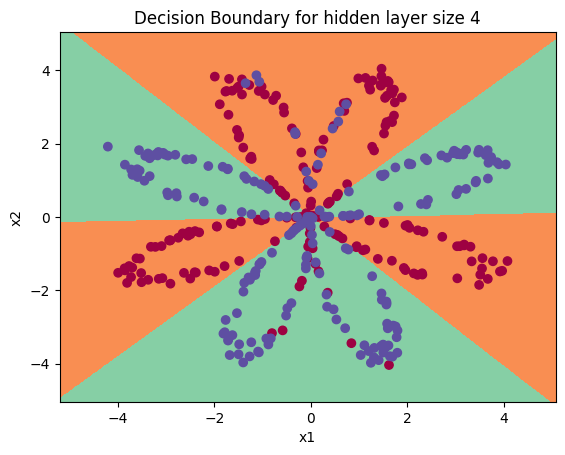

In [10]:
def predict(parameters, X):
    """
    Using the learned parameters, predicts a class for each example in X

    Arguments:
    parameters -- python dictionary containing your parameters
    X -- input data of size (n_x, m)

    Returns
    predictions -- vector of predictions of our model (red: 0 / blue: 1)
    """

    # Computes probabilities using forward propagation, and classifies to 0/1 using 0.5 as the threshold.
    #(≈ 2 lines of code)
    # A2, cache = ...
    # predictions = ...
    # YOUR CODE STARTS HERE
    A3, cache = forwared_propagation(parameters, X)
    predictions = (A3 > 0.5)
    # YOUR CODE ENDS HERE

    return predictions

# Build a model with a n_h-dimensional hidden layer
parameters = nn_model(X, Y, h1 = 6, h2 = 4, num_iterations = 10000, print_cost=True)

# Plot the decision boundary
plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
plt.title("Decision Boundary for hidden layer size " + str(4))